In [1]:
import pandas as pd
print(pd.__version__)


3.0.6


In [2]:
import numpy as np
print(np.__version__)
import matplotlib.pyplot as plt

2.5.4


In [3]:
df = pd.read_csv("../data/raw/journal_entries_4203.csv", sep=";")
df.head() # shows the first five lines of the document

,posting_id,document_date,posting_date,entered_date,gl_account,gl_account_name,amount,cd_flag,user,tax_rate,ref_id,text,promptly,weekend,nwh,label,marking,top_n,high_cash
0,a_1,2023-05-31,2023-05-31,2023-06-01 11:52:40,3400,"Cost of merchandise, 19% input tax",112.42,D,David,0.19,0,Rake,1,0,0,0,0,0,0
1,a_1,2023-05-31,2023-05-31,2023-06-01 11:52:40,1576,"Deductible input tax, 19%",21.36,D,David,0.19,0,Rake,1,0,0,0,0,0,0
2,a_1,2023-05-31,2023-05-31,2023-06-01 11:52:40,1600,Trade payables,133.78,C,David,0.19,0,Rake,1,0,0,0,0,0,0
3,a_2,2023-01-26,2023-01-26,2023-02-02 16:21:22,3400,"Cost of merchandise, 19% input tax",934.00,D,Bob,0.19,0,Lawn Mower,1,0,0,0,0,0,0
4,a_2,2023-01-26,2023-01-26,2023-02-02 16:21:22,1576,"Deductible input tax, 19%",177.46,D,Bob,0.19,0,Lawn Mower,1,0,0,0,0,0,0


In [4]:
df.info()  # information about the dataset

<class 'pandas.DataFrame'>
RangeIndex: 256232 entries, 0 to 256231
Data columns (total 19 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   posting_id       256232 non-null  str    
 1   document_date    256232 non-null  str    
 2   posting_date     256232 non-null  str    
 3   entered_date     256232 non-null  str    
 4   gl_account       256232 non-null  int64  
 5   gl_account_name  256232 non-null  str    
 6   amount           256232 non-null  float64
 7   cd_flag          256232 non-null  str    
 8   user             256232 non-null  str    
 9   tax_rate         256232 non-null  float64
 10  ref_id           256232 non-null  str    
 11  text             256232 non-null  str    
 12  promptly         256232 non-null  int64  
 13  weekend          256232 non-null  int64  
 14  nwh              256232 non-null  int64  
 15  label            256232 non-null  int64  
 16  marking          256232 non-null  int64  
 17  to

In [5]:
df["posting_date"].head()

0    2023-05-31
1    2023-05-31
2    2023-05-31
3    2023-01-26
4    2023-01-26
Name: posting_date, dtype: str

In [6]:
df["document_date"] = pd.to_datetime(df["document_date"])
df["posting_date"] = pd.to_datetime(df["posting_date"])
df["entered_date"] = pd.to_datetime(df["entered_date"])

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 256232 entries, 0 to 256231
Data columns (total 19 columns):
 #   Column           Non-Null Count   Dtype         
---  ------           --------------   -----         
 0   posting_id       256232 non-null  str           
 1   document_date    256232 non-null  datetime64[us]
 2   posting_date     256232 non-null  datetime64[us]
 3   entered_date     256232 non-null  datetime64[us]
 4   gl_account       256232 non-null  int64         
 5   gl_account_name  256232 non-null  str           
 6   amount           256232 non-null  float64       
 7   cd_flag          256232 non-null  str           
 8   user             256232 non-null  str           
 9   tax_rate         256232 non-null  float64       
 10  ref_id           256232 non-null  str           
 11  text             256232 non-null  str           
 12  promptly         256232 non-null  int64         
 13  weekend          256232 non-null  int64         
 14  nwh              256232 non-nul

In [8]:
df["posting_date"].min()

Timestamp('2023-01-02 00:00:00')

In [9]:
df["posting_date"].max()

Timestamp('2024-12-30 00:00:00')

In [10]:
df.dtypes  # data type of each column in the CSV

posting_id                    str
document_date      datetime64[us]
posting_date       datetime64[us]
entered_date       datetime64[us]
gl_account                  int64
gl_account_name               str
amount                    float64
cd_flag                       str
user                          str
tax_rate                  float64
ref_id                        str
text                          str
promptly                    int64
weekend                     int64
nwh                         int64
label                       int64
marking                     int64
top_n                       int64
high_cash                   int64
dtype: object

In [11]:
print("Lines:", len(df))  # number of rows in the table
print("Journal entries:", df["posting_id"].nunique())  # counts the distinct values in posting_id; unique() would list them
print("Accounts:", df["gl_account"].nunique())
print("Users:", df["user"].nunique())

Lines: 256232
Journal entries: 102429
Accounts: 25
Users: 6


In [12]:
df["cd_flag"].value_counts()  # how many times each value appears

cd_flag
D    135743
C    120489
Name: count, dtype: int64

In [13]:
df["signed_amount"] = np.where(df["cd_flag"] == "D", df["amount"], -df["amount"])
df[["posting_id", "cd_flag", "amount", "signed_amount"]].head()

,posting_id,cd_flag,amount,signed_amount
0,a_1,D,112.42,112.42
1,a_1,D,21.36,21.36
2,a_1,C,133.78,-133.78
3,a_2,D,934.00,934.00
4,a_2,D,177.46,177.46


In [14]:
is_a1 = df["posting_id"] == "a_1"
print(df[is_a1][["posting_id", "cd_flag", "amount", "signed_amount"]])
print("Sum:", df[is_a1]["signed_amount"].sum())

  posting_id cd_flag  amount  signed_amount
0        a_1       D  112.42         112.42
1        a_1       D   21.36          21.36
2        a_1       C  133.78        -133.78
Sum: 0.0


In [15]:
totals = df.groupby("posting_id")["signed_amount"].sum()
totals.head()


posting_id
a_1        0.0
a_10       0.0
a_100      0.0
a_1000     0.0
a_10000    0.0
Name: signed_amount, dtype: float64

In [16]:
is_p2 = df["posting_id"] == "p_2"
print("Lines:", is_p2.sum())
print(df[is_p2][["posting_id", "gl_account_name", "cd_flag", "amount", "signed_amount"]])
print("Sum:", df[is_p2]["signed_amount"].sum())

Lines: 4
       posting_id            gl_account_name cd_flag   amount  signed_amount
256224        p_2          Other liabilities       D  1490.90        1490.90
256225        p_2      Prior-period expenses       D    63.36          63.36
256226        p_2  Deductible input tax, 19%       D   295.31         295.31
256227        p_2             Trade payables       C  1849.57       -1849.57
Sum: 0.0


In [17]:
is_not_zero = totals != 0

print("Entries with a non-zero total:", is_not_zero.sum())

print(totals[is_not_zero].head())

is_unbalanced = totals.round(2) != 0

print("Unbalanced entries:", is_unbalanced.sum())

Entries with a non-zero total: 19452
posting_id
a_1013   -2.273737e-13
a_1023    2.842171e-14
a_1029    2.842171e-14
a_1050    7.105427e-15
a_106     3.552714e-15
Name: signed_amount, dtype: float64
Unbalanced entries: 0


In [18]:
df["prefix"] = df["posting_id"].str.split("_").str[0]
print(df[["posting_id", "prefix"]].head())
print(df["prefix"].value_counts())


  posting_id prefix
0        a_1      a
1        a_1      a
2        a_1      a
3        a_2      a
4        a_2      a
prefix
a     24982
aa    24872
d     20000
e     20000
ad    20000
ae    20000
b     19986
ab    19908
c     17500
ac    17422
f      9982
af     9976
g      7490
ag     7478
h      5000
ah     4990
i      2500
ai     2486
xa      734
x       731
r       180
p        15
Name: count, dtype: int64


In [19]:
entries_per_prefix = df.groupby("prefix")["posting_id"].nunique()
print(entries_per_prefix)

prefix
a     9991
aa    9936
ab    7954
ac    6961
ad    8000
ae    8000
af    3988
ag    2989
ah    1995
ai     993
b     7993
c     7000
d     8000
e     8000
f     3991
g     2995
h     2000
i     1000
p        6
r       60
x      288
xa     289
Name: posting_id, dtype: int64


In [20]:
is_prefix_a = df["prefix"] == "a"
is_prefix_aa = df["prefix"] == "aa"

print(df[is_prefix_a]["posting_date"].min())
print(df[is_prefix_a]["posting_date"].max())

print(df[is_prefix_aa]["posting_date"].min())
print(df[is_prefix_aa]["posting_date"].max())


2023-01-02 00:00:00
2024-03-06 00:00:00
2024-01-01 00:00:00
2024-12-30 00:00:00


In [21]:
is_prefix_c = df["prefix"] == "c"

print(df[is_prefix_a]["gl_account_name"].value_counts())
print(df[is_prefix_c]["gl_account_name"].value_counts())

gl_account_name
Trade payables                        9975
Cost of merchandise, 19% input tax    5000
Deductible input tax, 19%             5000
Bank (Postbank)                       4966
Cash-in-hand                            29
Bank                                    12
Name: count, dtype: int64
gl_account_name
Trade receivables    7000
Revenue, 19%         3500
VAT, 19%             3500
Bank (Postbank)      3500
Name: count, dtype: int64


In [22]:
is_2024 = df["posting_date"] >= "2024-01-01"
print(df[is_prefix_a & is_2024]["gl_account_name"].value_counts())

gl_account_name
Trade payables     93
Bank (Postbank)    90
Cash-in-hand        3
Name: count, dtype: int64


In [23]:
is_from_2023 = df["posting_date"] >= "2023-01-01"
is_before_2024 = df["posting_date"] <= "2023-12-31"
print(df[is_prefix_c & is_from_2023 & is_before_2024]["gl_account_name"].value_counts())
print(df[is_prefix_c & is_2024]["gl_account_name"].value_counts())

gl_account_name
Trade receivables    6979
Revenue, 19%         3500
VAT, 19%             3500
Bank (Postbank)      3479
Name: count, dtype: int64
gl_account_name
Bank (Postbank)      21
Trade receivables    21
Name: count, dtype: int64


In [24]:
is_anomaly = df["label"] == 1
print(df[is_anomaly]["prefix"].value_counts())

prefix
a     211
g     207
f     204
ag    202
aa    194
af    190
ad    182
d     151
ah     77
h      56
c      51
e      49
i      47
ac     42
ae     38
ai     37
b      31
ab     27
x       7
xa      5
Name: count, dtype: int64


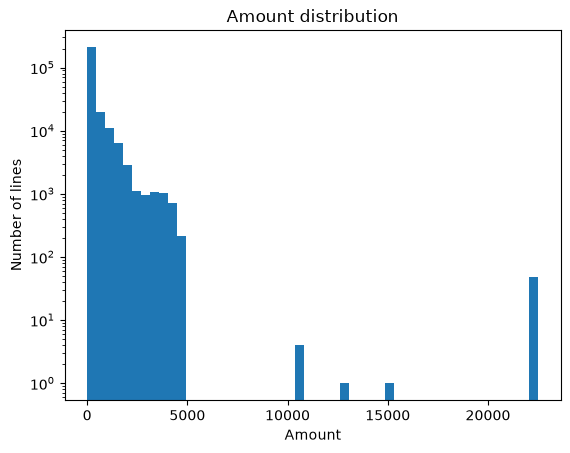

In [25]:
plt.hist(df["amount"], bins=50)
plt.title("Amount distribution")
plt.xlabel("Amount")
plt.ylabel("Number of lines")
plt.yscale("log")
plt.show()

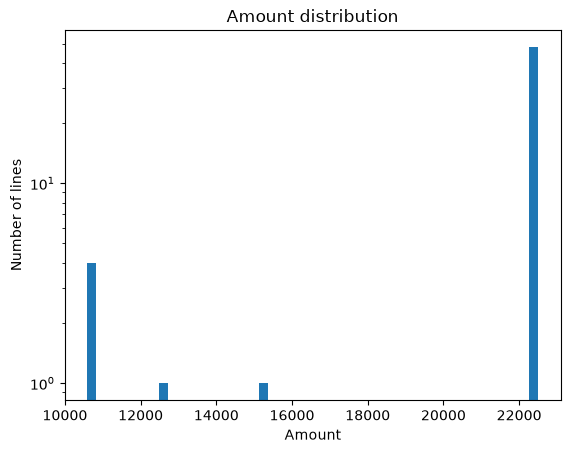

In [26]:
is_amount_5000_plus = df["amount"] >= 5000

plt.hist(df[is_amount_5000_plus]["amount"], bins=50)
plt.title("Amount distribution")
plt.xlabel("Amount")
plt.ylabel("Number of lines")
plt.yscale("log")
plt.show()


In [27]:
df[is_amount_5000_plus][["posting_id", "posting_date", "gl_account_name", "cd_flag", "amount", "text"]]


,posting_id,posting_date,gl_account_name,cd_flag,amount,text
127013,x_16,2023-01-05,Rent immovable property,D,22500.00,Rent January
127014,x_16,2023-01-05,Bank (Postbank),C,22500.00,Rent January
127076,x_41,2023-02-06,Rent immovable property,D,22500.00,Rent February
127077,x_41,2023-02-06,Bank (Postbank),C,22500.00,Rent February
127137,x_65,2023-03-03,Rent immovable property,D,22500.00,Rent March
127138,x_65,2023-03-03,Bank (Postbank),C,22500.00,Rent March
127198,x_89,2023-04-03,Rent immovable property,D,22500.00,Rent April
127199,x_89,2023-04-03,Bank (Postbank),C,22500.00,Rent April
127259,x_113,2023-05-03,Rent immovable property,D,22500.00,Rent May
127260,x_113,2023-05-03,Bank (Postbank),C,22500.00,Rent May


In [28]:
# 1. Journal entries (not lines) per user
entries_per_user = df.groupby("user")["posting_id"].nunique()
print(entries_per_user)

# 2. Anomaly rate per user, as a percentage
anomaly_rate_per_user = df.groupby("user")["label"].mean() * 100
print(anomaly_rate_per_user.round(2))



user
Alice      26175
Bob        32290
Charlie     6354
David      17802
Fred        6951
Max        12857
Name: posting_id, dtype: int64
user
Alice      0.06
Bob        0.07
Charlie    0.08
David      0.87
Fred       5.44
Max        1.78
Name: label, dtype: float64


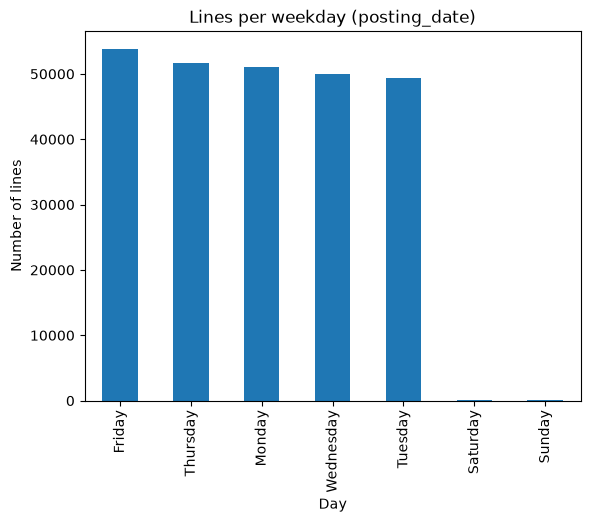

In [29]:
# New column with the weekday name of the posting (accounting) date
df["posting_weekday"] = df["posting_date"].dt.day_name()

# Count lines per day (sorted from most to least, not Monday-Tuesday-…)
lines_per_day = df["posting_weekday"].value_counts()
lines_per_day.plot(kind="bar")
plt.title("Lines per weekday (posting_date)")
plt.xlabel("Day")
plt.ylabel("Number of lines")
plt.show()


In [30]:
import duckdb

In [31]:
duckdb.sql("Select * FROM df LIMIT 5")

┌────────────┬─────────────────────┬─────────────────────┬─────────────────────┬────────────┬────────────────────────────────────┬────────┬─────────┬─────────┬──────────┬─────────┬────────────┬──────────┬─────────┬───────┬───────┬─────────┬───────┬───────────┬───────────────┬─────────┬─────────────────┐
│ posting_id │    document_date    │    posting_date     │    entered_date     │ gl_account │          gl_account_name           │ amount │ cd_flag │  user   │ tax_rate │ ref_id  │    text    │ promptly │ weekend │  nwh  │ label │ marking │ top_n │ high_cash │ signed_amount │ prefix  │ posting_weekday │
│  varchar   │      timestamp      │      timestamp      │      timestamp      │   int64    │              varchar               │ double │ varchar │ varchar │  double  │ varchar │  varchar   │  int64   │  int64  │ int64 │ int64 │  int64  │ int64 │   int64   │    double     │ varchar │     varchar     │
├────────────┼─────────────────────┼─────────────────────┼─────────────────────┼─────

In [32]:
duckdb.sql(
    """
    SELECT posting_id, gl_account_name, cd_flag, amount
    FROM df
    WHERE posting_id = 'a_1'
    """
)

┌────────────┬────────────────────────────────────┬─────────┬────────┐
│ posting_id │          gl_account_name           │ cd_flag │ amount │
│  varchar   │              varchar               │ varchar │ double │
├────────────┼────────────────────────────────────┼─────────┼────────┤
│ a_1        │ Cost of merchandise, 19% input tax │ D       │ 112.42 │
│ a_1        │ Deductible input tax, 19%          │ D       │  21.36 │
│ a_1        │ Trade payables                     │ C       │ 133.78 │
└────────────┴────────────────────────────────────┴─────────┴────────┘

In [33]:
duckdb.sql(
    """
    SELECT 
        COUNT(*) AS lines,
        COUNT(DISTINCT posting_id) AS entries
    FROM df    
    """
)

┌────────┬─────────┐
│ lines  │ entries │
│ int64  │  int64  │
├────────┼─────────┤
│ 256232 │  102429 │
└────────┴─────────┘

In [34]:
duckdb.sql(
    """
    SELECT
        user,
        COUNT(DISTINCT posting_id) AS entries,
        ROUND(AVG(label) * 100, 2) AS anomaly_rate
    FROM df
    GROUP BY user
    ORDER BY anomaly_rate DESC
    """
)

┌─────────┬─────────┬──────────────┐
│  user   │ entries │ anomaly_rate │
│ varchar │  int64  │    double    │
├─────────┼─────────┼──────────────┤
│ Fred    │    6951 │         5.44 │
│ Max     │   12857 │         1.78 │
│ David   │   17802 │         0.87 │
│ Charlie │    6354 │         0.08 │
│ Bob     │   32290 │         0.07 │
│ Alice   │   26175 │         0.06 │
└─────────┴─────────┴──────────────┘

In [35]:
duckdb.sql(
    """
    SELECT
        dayname(entered_date) AS entered_weekday,
        COUNT(*) AS lines,
        ROUND(AVG(label) * 100, 2) AS anomaly_rate
    FROM df
    GROUP BY entered_weekday
    ORDER BY anomaly_rate DESC
    """
)

┌─────────────────┬───────┬──────────────┐
│ entered_weekday │ lines │ anomaly_rate │
│     varchar     │ int64 │    double    │
├─────────────────┼───────┼──────────────┤
│ Sunday          │ 16551 │         2.14 │
│ Saturday        │ 14986 │         1.95 │
│ Friday          │ 45317 │         0.85 │
│ Monday          │ 46811 │          0.7 │
│ Wednesday       │ 42781 │         0.59 │
│ Tuesday         │ 45172 │         0.47 │
│ Thursday        │ 44614 │         0.43 │
└─────────────────┴───────┴──────────────┘

In [36]:
duckdb.sql(
    """
    SELECT
        COUNT(*) AS lines,
        SUM(label) AS anomalies
    FROM df
    """
)

┌────────┬───────────┐
│ lines  │ anomalies │
│ int64  │  int128   │
├────────┼───────────┤
│ 256232 │      2008 │
└────────┴───────────┘

In [37]:
duckdb.sql(
    """
        SELECT
            COUNT(*) AS lines,
            SUM(label) AS anomalies
        FROM df
        WHERE dayname(entered_date) = 'Saturday' OR dayname(entered_date) = 'Sunday' 
        """
)

┌───────┬───────────┐
│ lines │ anomalies │
│ int64 │  int128   │
├───────┼───────────┤
│ 31537 │       646 │
└───────┴───────────┘

In [38]:
duckdb.sql(
    """
    SELECT
        gl_account_name,
        COUNT(*) AS lines,
        SUM(label) AS anomalies,
        ROUND(AVG(label) * 100, 2) AS anomaly_rate
    FROM df
    GROUP BY gl_account_name
    ORDER BY anomaly_rate DESC
    """
)

┌────────────────────────────────────┬───────┬───────────┬──────────────┐
│          gl_account_name           │ lines │ anomalies │ anomaly_rate │
│              varchar               │ int64 │  int128   │    double    │
├────────────────────────────────────┼───────┼───────────┼──────────────┤
│ Bank                               │    60 │        60 │        100.0 │
│ Rent immovable property            │    24 │         2 │         8.33 │
│ Gas, electricity, water            │    24 │         1 │         4.17 │
│ Cash-in-hand                       │ 12060 │       236 │         1.96 │
│ Trade payables                     │ 65843 │       636 │         0.97 │
│ Wages and salaries                 │   120 │         1 │         0.83 │
│ Statutory social security expenses │   120 │         1 │         0.83 │
│ Bank (Postbank)                    │ 39301 │       304 │         0.77 │
│ Cost of merchandise, 19% input tax │ 33060 │       215 │         0.65 │
│ Deductible input tax, 19%          │